In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import pyarrow
from pathlib import Path

In [2]:
BASE_DIR = Path.cwd().resolve().parent
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

In [3]:
df_cap200b_1 = pd.read_parquet(RAW_DIR / "04_CAP200B_1.parquet")
df_caratula = pd.read_parquet(RAW_DIR / "CARATULA.parquet")

In [4]:
ruta_mapa = BASE_DIR / "data"/"processed"/"LIM_DEPARTAMENTAL_PERU_MIN.json"
ruta_provinvial = BASE_DIR / "data"/"processed"/"LIM_PROVINCIAL_PERU.json"
peru = gpd.read_file(ruta_mapa)
provincias_peru = gpd.read_file(ruta_provinvial)

# 1. Análisis de la región de Piura

In [5]:
provincias = provincias_peru.copy()
provinvias_piu = provincias_peru[
    provincias_peru["NOMBDEP"].str.upper().eq("PIURA")
]
provinvias_piu.head(8)

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry
58,62,59,20,PIURA,02,AYABACA,AYABACA,2002,0.424331,3.985580,58,3.985580,0.424331,"POLYGON ((-79.39355 -4.83617, -79.39857 -4.825..."
59,63,60,20,PIURA,03,HUANCABAMBA,HUANCABAMBA,2003,0.348857,4.456044,59,4.456044,0.348857,"POLYGON ((-79.21004 -4.96585, -79.21014 -4.965..."
60,64,61,20,PIURA,04,MORROPON,CHULUCANAS,2004,0.308884,3.444733,60,3.444733,0.308884,"POLYGON ((-79.64221 -5.10722, -79.64275 -5.106..."
61,65,62,20,PIURA,05,PAITA,PAITA,2005,0.138029,2.217273,61,2.217273,0.138029,"POLYGON ((-80.85955 -5.28064, -80.85943 -5.279..."
62,66,63,20,PIURA,01,PIURA,PIURA,2001,0.491585,4.724733,62,4.724733,0.491585,"POLYGON ((-80.22143 -4.59545, -80.22227 -4.594..."
63,67,64,20,PIURA,08,SECHURA,SECHURA,2008,0.518904,3.702383,63,3.702383,0.518904,"POLYGON ((-80.09237 -5.79509, -80.09249 -5.795..."
64,68,65,20,PIURA,06,SULLANA,SULLANA,2006,0.430481,4.929262,64,4.929262,0.430481,"POLYGON ((-80.28988 -4.43324, -80.28988 -4.433..."
65,69,66,20,PIURA,07,TALARA,TALARA,2007,0.238152,2.449033,65,2.449033,0.238152,"POLYGON ((-80.93638 -4.17824, -80.93727 -4.177..."


In [6]:
df_piura = df_cap200b_1[df_cap200b_1["NOMBREDD"]=="PIURA"].copy()

In [7]:
print(df_piura["NOMBREPV"].unique())
print(provinvias_piu["NOMBPROV"].unique())

<ArrowStringArray>
['SECHURA', 'MORROPON', 'HUANCABAMBA', 'AYABACA', 'PIURA']
Length: 5, dtype: str
<ArrowStringArray>
[    'AYABACA', 'HUANCABAMBA',    'MORROPON',       'PAITA',       'PIURA',
     'SECHURA',     'SULLANA',      'TALARA']
Length: 8, dtype: str


In [8]:
df_cap200b_1.loc[df_cap200b_1["NOMBREDD"] == "PIURA", "NOMBREPV"].unique()

<ArrowStringArray>
['SECHURA', 'MORROPON', 'HUANCABAMBA', 'AYABACA', 'PIURA']
Length: 5, dtype: str

In [9]:
# Qué provincias faltan:
provincias_sin_datos = set(provinvias_piu["NOMBPROV"]) - set(df_piura["NOMBREPV"])

print(provincias_sin_datos)

{'TALARA', 'SULLANA', 'PAITA'}


## 1.1. Factores que afectan la producción o superficie de los cultivos

In [10]:
cols_factores_piura = [f"P224E_{i}" for i in range(1, 8)]

factores_piura = df_piura[cols_factores_piura]

nombres_factores = [
    "huaycos_deslizamientos_derrumbes",
    "inundaciones",
    "plagas_enfermedades",
    "helada",
    "Granizada",
    "sequía",
    "Otros"
]

tabla_lam = pd.DataFrame({
    "factor": nombres_factores,
    "si_afecto": [factores_piura[c].eq(1).sum() for c in cols_factores_piura],
    "no_afecto": [factores_piura[c].eq(0).sum() for c in cols_factores_piura]
})

tabla_lam["porcentaje_falla"] = (
    tabla_lam["si_afecto"] /
    (tabla_lam["si_afecto"] + tabla_lam["no_afecto"]) * 100
).round(2)

tabla_lam

,factor,si_afecto,no_afecto,porcentaje_falla
0,huaycos_deslizamientos_derrumbes,3,249,1.19
1,inundaciones,75,177,29.76
2,plagas_enfermedades,80,172,31.75
3,helada,7,245,2.78
4,Granizada,0,252,0.00
5,sequía,32,220,12.70
6,Otros,90,162,35.71


###  1.1.1. Afectada por inundaciones

In [33]:
df_piura["P224B_NOM"].value_counts().sum()

np.int64(252)

In [32]:
df_piura["P224B_COD"].value_counts().sum()

np.int64(252)

In [34]:
cultivos_inundaciones = (
    df_piura[df_piura["P224E_2"] == 1]
    .groupby(["P224B_COD", "P224B_NOM"])
    .size()
    .reset_index(name="cantidad")
    .sort_values("cantidad", ascending=False)
)
cultivos_inundaciones

,P224B_COD,P224B_NOM,cantidad
4,2108,MAIZ AMILACEO,26
3,2107,MAIZ AMARILLO DURO,17
8,2803,ALGODON,6
15,2951,ZARANDAJA,5
14,2914,FRIJOL DE PALO,5
10,2907,FRIJOL BLANCO,3
7,2620,YUCA,3
11,2908,FRIJOL CABALLERO,2
6,2113,TRIGO,1
5,2109,MAIZ CHOCLO,1


In [39]:
cultivos_inundaciones_prov = (
    df_piura[df_piura["P224E_2"] == 1]
    .groupby(["NOMBREPV", "P224B_COD", "P224B_NOM"])
    .size()
    .reset_index(name="cantidad")
    .sort_values(["NOMBREPV", "cantidad"], ascending=[True, False])
)

cultivos_inundaciones_prov

,NOMBREPV,P224B_COD,P224B_NOM,cantidad
1,AYABACA,2108,MAIZ AMILACEO,25
0,AYABACA,2107,MAIZ AMARILLO DURO,11
7,AYABACA,2914,FRIJOL DE PALO,5
8,AYABACA,2951,ZARANDAJA,5
2,AYABACA,2620,YUCA,3
4,AYABACA,2907,FRIJOL BLANCO,2
5,AYABACA,2908,FRIJOL CABALLERO,2
3,AYABACA,2901,ARVEJA,1
6,AYABACA,2910,FRIJOL CANARIO,1
9,HUANCABAMBA,2107,MAIZ AMARILLO DURO,1


In [11]:
df_info = pd.crosstab(df_piura["NOMBREPV"], df_piura["P224E_2"])
df_info

P224E_2,0,1
NOMBREPV,,
AYABACA,93,55
HUANCABAMBA,21,2
MORROPON,24,3
PIURA,27,14
SECHURA,12,1


In [12]:
#indica el número medio de terreno registrado por observación en cada provincia.
resumen_inun_piura = (
    df_piura.groupby("NOMBREPV")["P224E_2"]
    .agg(
        promedio="mean",
        n="count"
    )
    .reset_index()
)
resumen_inun_piura

,NOMBREPV,promedio,n
0,AYABACA,0.371622,148
1,HUANCABAMBA,0.086957,23
2,MORROPON,0.111111,27
3,PIURA,0.341463,41
4,SECHURA,0.076923,13


In [13]:
piura_merge_inun = provinvias_piu.merge(
    resumen_inun_piura,
    left_on= "NOMBPROV",
    right_on = "NOMBREPV",
    how="left"
).copy()
piura_merge_inun

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry,NOMBREPV,promedio,n
0,62,59,20,PIURA,02,AYABACA,AYABACA,2002,0.424331,3.985580,58,3.985580,0.424331,"POLYGON ((-79.39355 -4.83617, -79.39857 -4.825...",AYABACA,0.371622,148.0
1,63,60,20,PIURA,03,HUANCABAMBA,HUANCABAMBA,2003,0.348857,4.456044,59,4.456044,0.348857,"POLYGON ((-79.21004 -4.96585, -79.21014 -4.965...",HUANCABAMBA,0.086957,23.0
2,64,61,20,PIURA,04,MORROPON,CHULUCANAS,2004,0.308884,3.444733,60,3.444733,0.308884,"POLYGON ((-79.64221 -5.10722, -79.64275 -5.106...",MORROPON,0.111111,27.0
3,65,62,20,PIURA,05,PAITA,PAITA,2005,0.138029,2.217273,61,2.217273,0.138029,"POLYGON ((-80.85955 -5.28064, -80.85943 -5.279...",NaN,NaN,NaN
4,66,63,20,PIURA,01,PIURA,PIURA,2001,0.491585,4.724733,62,4.724733,0.491585,"POLYGON ((-80.22143 -4.59545, -80.22227 -4.594...",PIURA,0.341463,41.0
5,67,64,20,PIURA,08,SECHURA,SECHURA,2008,0.518904,3.702383,63,3.702383,0.518904,"POLYGON ((-80.09237 -5.79509, -80.09249 -5.795...",SECHURA,0.076923,13.0
6,68,65,20,PIURA,06,SULLANA,SULLANA,2006,0.430481,4.929262,64,4.929262,0.430481,"POLYGON ((-80.28988 -4.43324, -80.28988 -4.433...",NaN,NaN,NaN
7,69,66,20,PIURA,07,TALARA,TALARA,2007,0.238152,2.449033,65,2.449033,0.238152,"POLYGON ((-80.93638 -4.17824, -80.93727 -4.177...",NaN,NaN,NaN


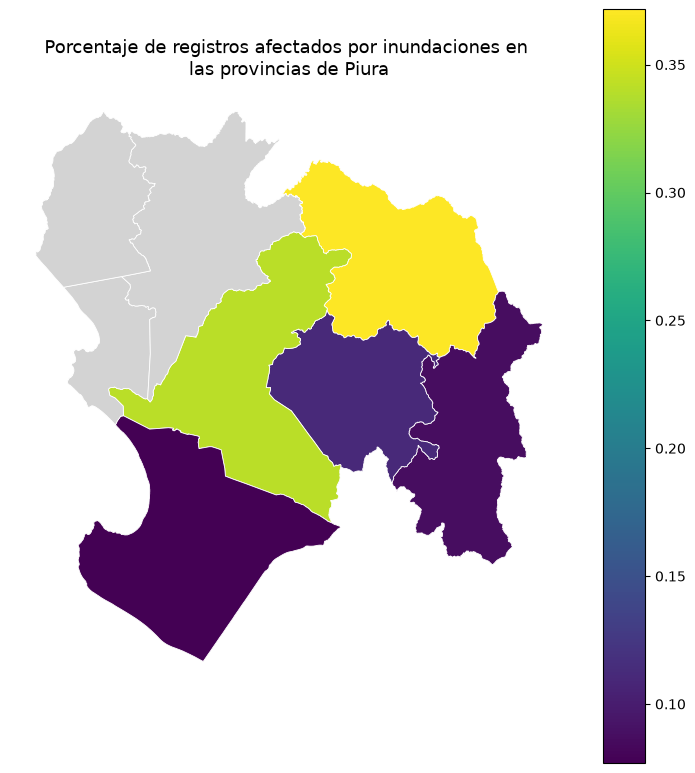

In [14]:
fig, ax = plt.subplots(figsize=(9, 11))

piura_merge_inun.plot(
    column="promedio",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    }
)

ax.set_title(
    "Porcentaje de registros afectados por inundaciones en \n"
    "las provincias de Piura",
    fontsize=13
)

ax.set_axis_off()
plt.show()

###  1.1.2. Afectada por plagas y/o enfermadades

In [35]:
cultivos_plagas = (
    df_piura[df_piura["P224E_3"] == 1]
    .groupby(["P224B_COD", "P224B_NOM"])
    .size()
    .reset_index(name="cantidad")
    .sort_values("cantidad", ascending=False)
)
cultivos_plagas

,P224B_COD,P224B_NOM,cantidad
17,2803,ALGODON,22
7,2107,MAIZ AMARILLO DURO,6
18,2901,ARVEJA,6
8,2108,MAIZ AMILACEO,6
1,1147,MANGO,4
6,2101,ARROZ CASCARA,3
13,2608,OCA,3
16,2612,PAPA BLANCA,3
4,1183,TAPERIBA,2
3,1159,PACAE,2


In [40]:
cultivos_plagas_prov = (
    df_piura[df_piura["P224E_3"] == 1]
    .groupby(["NOMBREPV", "P224B_COD", "P224B_NOM"])
    .size()
    .reset_index(name="cantidad")
    .sort_values(["NOMBREPV", "cantidad"], ascending=[True, False])
)

cultivos_plagas_prov

,NOMBREPV,P224B_COD,P224B_NOM,cantidad
1,AYABACA,2108,MAIZ AMILACEO,3
5,AYABACA,2612,PAPA BLANCA,2
6,AYABACA,2901,ARVEJA,2
8,AYABACA,2908,FRIJOL CABALLERO,2
0,AYABACA,2107,MAIZ AMARILLO DURO,1
2,AYABACA,2113,TRIGO,1
3,AYABACA,2608,OCA,1
4,AYABACA,2609,OLLUCO,1
7,AYABACA,2907,FRIJOL BLANCO,1
9,AYABACA,2951,ZARANDAJA,1


In [15]:
df_info = pd.crosstab(df_piura["NOMBREPV"], df_piura["P224E_3"])
df_info

P224E_3,0,1
NOMBREPV,,
AYABACA,133,15
HUANCABAMBA,4,19
MORROPON,13,14
PIURA,18,23
SECHURA,4,9


In [16]:
#indica el número medio de terreno registrado por observación en cada provincia.
resumen_plagas_piura = (
    df_piura.groupby("NOMBREPV")["P224E_3"]
    .agg(
        promedio="mean",
        n="count"
    )
    .reset_index()
)
resumen_plagas_piura

,NOMBREPV,promedio,n
0,AYABACA,0.101351,148
1,HUANCABAMBA,0.826087,23
2,MORROPON,0.518519,27
3,PIURA,0.560976,41
4,SECHURA,0.692308,13


In [17]:
piura_merge_plagas = provinvias_piu.merge(
    resumen_plagas_piura,
    left_on= "NOMBPROV",
    right_on = "NOMBREPV",
    how="left"
).copy()
piura_merge_plagas

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry,NOMBREPV,promedio,n
0,62,59,20,PIURA,02,AYABACA,AYABACA,2002,0.424331,3.985580,58,3.985580,0.424331,"POLYGON ((-79.39355 -4.83617, -79.39857 -4.825...",AYABACA,0.101351,148.0
1,63,60,20,PIURA,03,HUANCABAMBA,HUANCABAMBA,2003,0.348857,4.456044,59,4.456044,0.348857,"POLYGON ((-79.21004 -4.96585, -79.21014 -4.965...",HUANCABAMBA,0.826087,23.0
2,64,61,20,PIURA,04,MORROPON,CHULUCANAS,2004,0.308884,3.444733,60,3.444733,0.308884,"POLYGON ((-79.64221 -5.10722, -79.64275 -5.106...",MORROPON,0.518519,27.0
3,65,62,20,PIURA,05,PAITA,PAITA,2005,0.138029,2.217273,61,2.217273,0.138029,"POLYGON ((-80.85955 -5.28064, -80.85943 -5.279...",NaN,NaN,NaN
4,66,63,20,PIURA,01,PIURA,PIURA,2001,0.491585,4.724733,62,4.724733,0.491585,"POLYGON ((-80.22143 -4.59545, -80.22227 -4.594...",PIURA,0.560976,41.0
5,67,64,20,PIURA,08,SECHURA,SECHURA,2008,0.518904,3.702383,63,3.702383,0.518904,"POLYGON ((-80.09237 -5.79509, -80.09249 -5.795...",SECHURA,0.692308,13.0
6,68,65,20,PIURA,06,SULLANA,SULLANA,2006,0.430481,4.929262,64,4.929262,0.430481,"POLYGON ((-80.28988 -4.43324, -80.28988 -4.433...",NaN,NaN,NaN
7,69,66,20,PIURA,07,TALARA,TALARA,2007,0.238152,2.449033,65,2.449033,0.238152,"POLYGON ((-80.93638 -4.17824, -80.93727 -4.177...",NaN,NaN,NaN


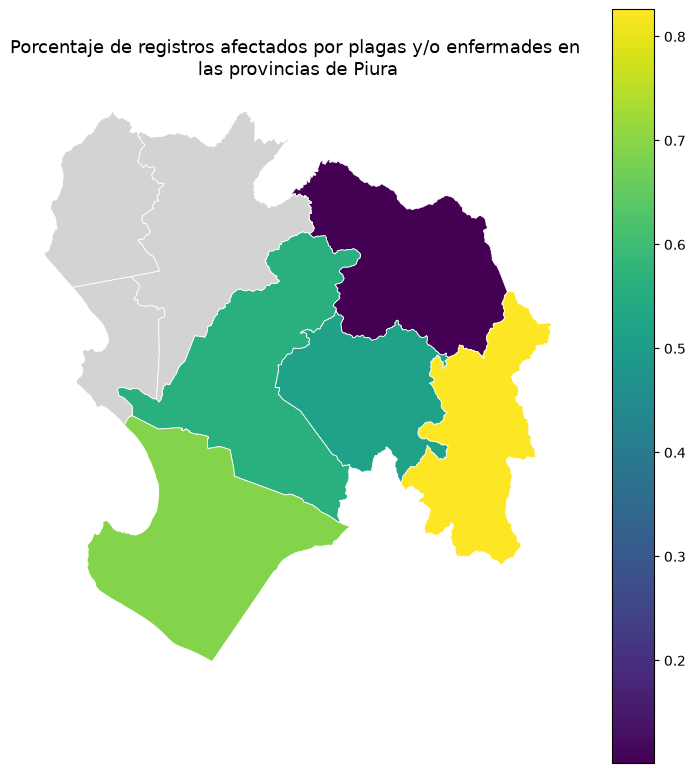

In [18]:
fig, ax = plt.subplots(figsize=(9, 11))

piura_merge_plagas.plot(
    column="promedio",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    }
)

ax.set_title(
    "Porcentaje de registros afectados por plagas y/o enfermades en \n"
    "las provincias de Piura",
    fontsize=13
)

ax.set_axis_off()
plt.show()

###  1.1.3. Afectada por sequía

In [36]:
cultivos_sequia = (
    df_piura[df_piura["P224E_6"] == 1]
    .groupby(["P224B_COD", "P224B_NOM"])
    .size()
    .reset_index(name="cantidad")
    .sort_values("cantidad", ascending=False)
)
cultivos_sequia

,P224B_COD,P224B_NOM,cantidad
7,2107,MAIZ AMARILLO DURO,10
1,1147,MANGO,4
5,1183,TAPERIBA,2
11,2911,FRIJOL CAUPI,2
10,2809,CAÃ‘A DE AZUCAR PARA CHANCACA,2
8,2108,MAIZ AMILACEO,2
4,1171,PLATANO,2
6,1203,CAFE PERGAMINO,1
3,1159,PACAE,1
0,1145,MAMEY,1


In [41]:
cultivos_sequia_prov = (
    df_piura[df_piura["P224E_6"] == 1]
    .groupby(["NOMBREPV", "P224B_COD", "P224B_NOM"])
    .size()
    .reset_index(name="cantidad")
    .sort_values(["NOMBREPV", "cantidad"], ascending=[True, False])
)

cultivos_sequia_prov

,NOMBREPV,P224B_COD,P224B_NOM,cantidad
0,AYABACA,2107,MAIZ AMARILLO DURO,1
1,AYABACA,2951,ZARANDAJA,1
3,HUANCABAMBA,2107,MAIZ AMARILLO DURO,2
4,HUANCABAMBA,2108,MAIZ AMILACEO,2
5,HUANCABAMBA,2809,CAÃ‘A DE AZUCAR PARA CHANCACA,2
2,HUANCABAMBA,1203,CAFE PERGAMINO,1
6,HUANCABAMBA,2930,FRIJOL PINTO,1
7,HUANCABAMBA,2942,HABA,1
14,MORROPON,2107,MAIZ AMARILLO DURO,7
9,MORROPON,1147,MANGO,2


In [19]:
df_info = pd.crosstab(df_piura["NOMBREPV"], df_piura["P224E_6"])
df_info

P224E_6,0,1
NOMBREPV,,
AYABACA,146,2
HUANCABAMBA,14,9
MORROPON,8,19
PIURA,39,2
SECHURA,13,0


In [20]:
#indica el número medio de terreno registrado por observación en cada provincia.
resumen_sequia_piura = (
    df_piura.groupby("NOMBREPV")["P224E_6"]
    .agg(
        promedio="mean",
        n="count"
    )
    .reset_index()
)
resumen_sequia_piura

,NOMBREPV,promedio,n
0,AYABACA,0.013514,148
1,HUANCABAMBA,0.391304,23
2,MORROPON,0.703704,27
3,PIURA,0.048780,41
4,SECHURA,0.000000,13


In [21]:
piura_merge_sequia = provinvias_piu.merge(
    resumen_sequia_piura,
    left_on= "NOMBPROV",
    right_on = "NOMBREPV",
    how="left"
).copy()
piura_merge_sequia

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry,NOMBREPV,promedio,n
0,62,59,20,PIURA,02,AYABACA,AYABACA,2002,0.424331,3.985580,58,3.985580,0.424331,"POLYGON ((-79.39355 -4.83617, -79.39857 -4.825...",AYABACA,0.013514,148.0
1,63,60,20,PIURA,03,HUANCABAMBA,HUANCABAMBA,2003,0.348857,4.456044,59,4.456044,0.348857,"POLYGON ((-79.21004 -4.96585, -79.21014 -4.965...",HUANCABAMBA,0.391304,23.0
2,64,61,20,PIURA,04,MORROPON,CHULUCANAS,2004,0.308884,3.444733,60,3.444733,0.308884,"POLYGON ((-79.64221 -5.10722, -79.64275 -5.106...",MORROPON,0.703704,27.0
3,65,62,20,PIURA,05,PAITA,PAITA,2005,0.138029,2.217273,61,2.217273,0.138029,"POLYGON ((-80.85955 -5.28064, -80.85943 -5.279...",NaN,NaN,NaN
4,66,63,20,PIURA,01,PIURA,PIURA,2001,0.491585,4.724733,62,4.724733,0.491585,"POLYGON ((-80.22143 -4.59545, -80.22227 -4.594...",PIURA,0.048780,41.0
5,67,64,20,PIURA,08,SECHURA,SECHURA,2008,0.518904,3.702383,63,3.702383,0.518904,"POLYGON ((-80.09237 -5.79509, -80.09249 -5.795...",SECHURA,0.000000,13.0
6,68,65,20,PIURA,06,SULLANA,SULLANA,2006,0.430481,4.929262,64,4.929262,0.430481,"POLYGON ((-80.28988 -4.43324, -80.28988 -4.433...",NaN,NaN,NaN
7,69,66,20,PIURA,07,TALARA,TALARA,2007,0.238152,2.449033,65,2.449033,0.238152,"POLYGON ((-80.93638 -4.17824, -80.93727 -4.177...",NaN,NaN,NaN


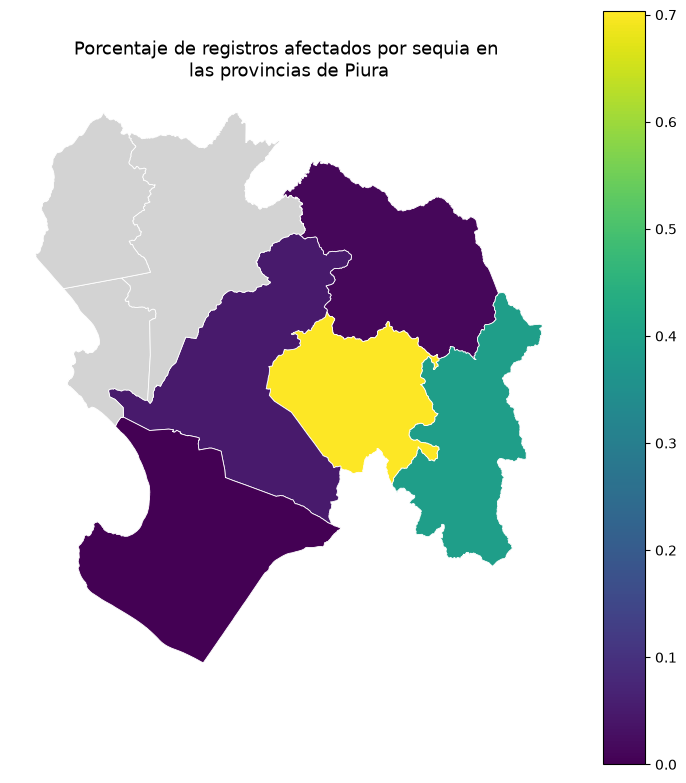

In [22]:
fig, ax = plt.subplots(figsize=(9, 11))

piura_merge_sequia.plot(
    column="promedio",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    }
)

ax.set_title(
    "Porcentaje de registros afectados por sequia en \n"
    "las provincias de Piura",
    fontsize=13
)

ax.set_axis_off()
plt.show()

###  1.1.4. Afectada por otros motivos

In [37]:
cultivos_otros = (
    df_piura[df_piura["P224E_7"] == 1]
    .groupby(["P224B_COD", "P224B_NOM"])
    .size()
    .reset_index(name="cantidad")
    .sort_values("cantidad", ascending=False)
)
cultivos_otros

,P224B_COD,P224B_NOM,cantidad
3,2108,MAIZ AMILACEO,15
12,2910,FRIJOL CANARIO,15
14,2929,FRIJOL PANAMITO,14
2,2107,MAIZ AMARILLO DURO,12
11,2908,FRIJOL CABALLERO,9
9,2901,ARVEJA,6
0,1147,MANGO,3
8,2803,ALGODON,3
10,2907,FRIJOL BLANCO,3
4,2109,MAIZ CHOCLO,2


In [42]:
cultivos_otros_prov = (
    df_piura[df_piura["P224E_7"] == 1]
    .groupby(["NOMBREPV", "P224B_COD", "P224B_NOM"])
    .size()
    .reset_index(name="cantidad")
    .sort_values(["NOMBREPV", "cantidad"], ascending=[True, False])
)

cultivos_otros_prov

,NOMBREPV,P224B_COD,P224B_NOM,cantidad
1,AYABACA,2108,MAIZ AMILACEO,15
7,AYABACA,2910,FRIJOL CANARIO,15
9,AYABACA,2929,FRIJOL PANAMITO,14
0,AYABACA,2107,MAIZ AMARILLO DURO,9
6,AYABACA,2908,FRIJOL CABALLERO,9
4,AYABACA,2901,ARVEJA,5
5,AYABACA,2907,FRIJOL BLANCO,3
2,AYABACA,2109,MAIZ CHOCLO,2
3,AYABACA,2113,TRIGO,2
8,AYABACA,2911,FRIJOL CAUPI,1


In [23]:
df_info = pd.crosstab(df_piura["NOMBREPV"], df_piura["P224E_7"])
df_info

P224E_7,0,1
NOMBREPV,,
AYABACA,73,75
HUANCABAMBA,19,4
MORROPON,26,1
PIURA,33,8
SECHURA,11,2


In [24]:
#indica el número medio de terreno registrado por observación en cada provincia.
resumen_otros_piura = (
    df_piura.groupby("NOMBREPV")["P224E_7"]
    .agg(
        promedio="mean",
        n="count"
    )
    .reset_index()
)
resumen_otros_piura

,NOMBREPV,promedio,n
0,AYABACA,0.506757,148
1,HUANCABAMBA,0.173913,23
2,MORROPON,0.037037,27
3,PIURA,0.195122,41
4,SECHURA,0.153846,13


In [25]:
piura_merge_otros = provinvias_piu.merge(
    resumen_otros_piura,
    left_on= "NOMBPROV",
    right_on = "NOMBREPV",
    how="left"
).copy()
piura_merge_otros

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry,NOMBREPV,promedio,n
0,62,59,20,PIURA,02,AYABACA,AYABACA,2002,0.424331,3.985580,58,3.985580,0.424331,"POLYGON ((-79.39355 -4.83617, -79.39857 -4.825...",AYABACA,0.506757,148.0
1,63,60,20,PIURA,03,HUANCABAMBA,HUANCABAMBA,2003,0.348857,4.456044,59,4.456044,0.348857,"POLYGON ((-79.21004 -4.96585, -79.21014 -4.965...",HUANCABAMBA,0.173913,23.0
2,64,61,20,PIURA,04,MORROPON,CHULUCANAS,2004,0.308884,3.444733,60,3.444733,0.308884,"POLYGON ((-79.64221 -5.10722, -79.64275 -5.106...",MORROPON,0.037037,27.0
3,65,62,20,PIURA,05,PAITA,PAITA,2005,0.138029,2.217273,61,2.217273,0.138029,"POLYGON ((-80.85955 -5.28064, -80.85943 -5.279...",NaN,NaN,NaN
4,66,63,20,PIURA,01,PIURA,PIURA,2001,0.491585,4.724733,62,4.724733,0.491585,"POLYGON ((-80.22143 -4.59545, -80.22227 -4.594...",PIURA,0.195122,41.0
5,67,64,20,PIURA,08,SECHURA,SECHURA,2008,0.518904,3.702383,63,3.702383,0.518904,"POLYGON ((-80.09237 -5.79509, -80.09249 -5.795...",SECHURA,0.153846,13.0
6,68,65,20,PIURA,06,SULLANA,SULLANA,2006,0.430481,4.929262,64,4.929262,0.430481,"POLYGON ((-80.28988 -4.43324, -80.28988 -4.433...",NaN,NaN,NaN
7,69,66,20,PIURA,07,TALARA,TALARA,2007,0.238152,2.449033,65,2.449033,0.238152,"POLYGON ((-80.93638 -4.17824, -80.93727 -4.177...",NaN,NaN,NaN


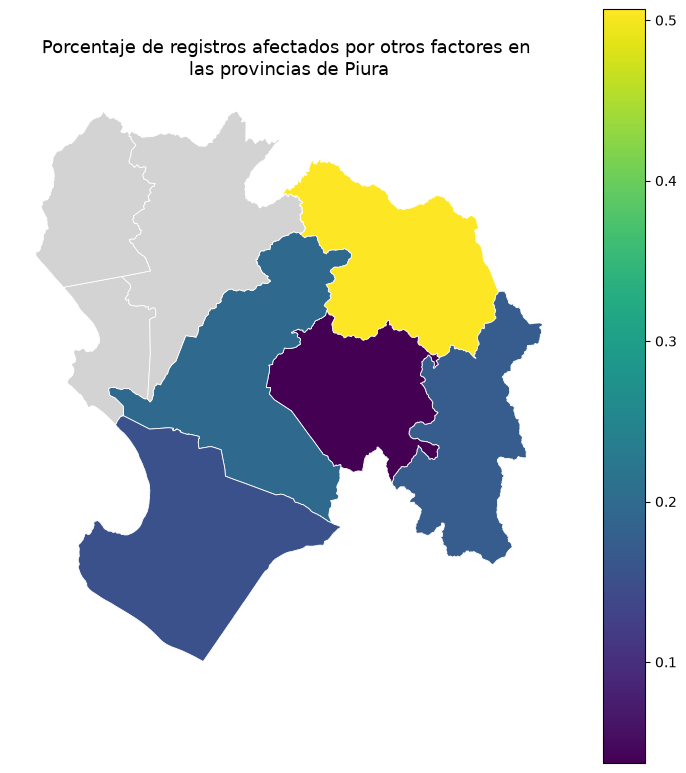

In [26]:
fig, ax = plt.subplots(figsize=(9, 11))

piura_merge_otros.plot(
    column="promedio",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    }
)

ax.set_title(
    "Porcentaje de registros afectados por otros factores en \n"
    "las provincias de Piura",
    fontsize=13
)

ax.set_axis_off()
plt.show()

In [27]:
df_piura["P224B_NOM"].value_counts()

P224B_NOM
MAIZ AMILACEO                    45
MAIZ AMARILLO DURO               43
ALGODON                          26
FRIJOL CANARIO                   17
FRIJOL CABALLERO                 15
FRIJOL PANAMITO                  15
ARVEJA                           13
MANGO                            10
ZARANDAJA                         8
FRIJOL BLANCO                     7
FRIJOL CAUPI                      5
MAIZ CHOCLO                       5
FRIJOL DE PALO                    5
TRIGO                             4
ARROZ CASCARA                     3
PLATANO                           3
PAPA BLANCA                       3
OCA                               3
YUCA                              3
PACAE                             2
TAPERIBA                          2
OLLUCO                            2
HABA                              2
CAÃ‘A DE AZUCAR PARA CHANCACA     2
NARANJO                           1
MAMEY                             1
ZAPALLO                           1
SANDIA            

## 1.2. Pérdida del 100% de su producción o de la superficie sembrada en los últimos 12 meses

In [28]:
ranking_cultivos_piura = (
    df_piura["P224B_NOM"]
    .dropna()
    .value_counts()
    .head(10)
    .reset_index()
)

ranking_cultivos_piura.columns = ["cultivo", "frecuencia"]
ranking_cultivos_piura

,cultivo,frecuencia
0,MAIZ AMILACEO,45
1,MAIZ AMARILLO DURO,43
2,ALGODON,26
3,FRIJOL CANARIO,17
4,FRIJOL CABALLERO,15
5,FRIJOL PANAMITO,15
6,ARVEJA,13
7,MANGO,10
8,ZARANDAJA,8
9,FRIJOL BLANCO,7


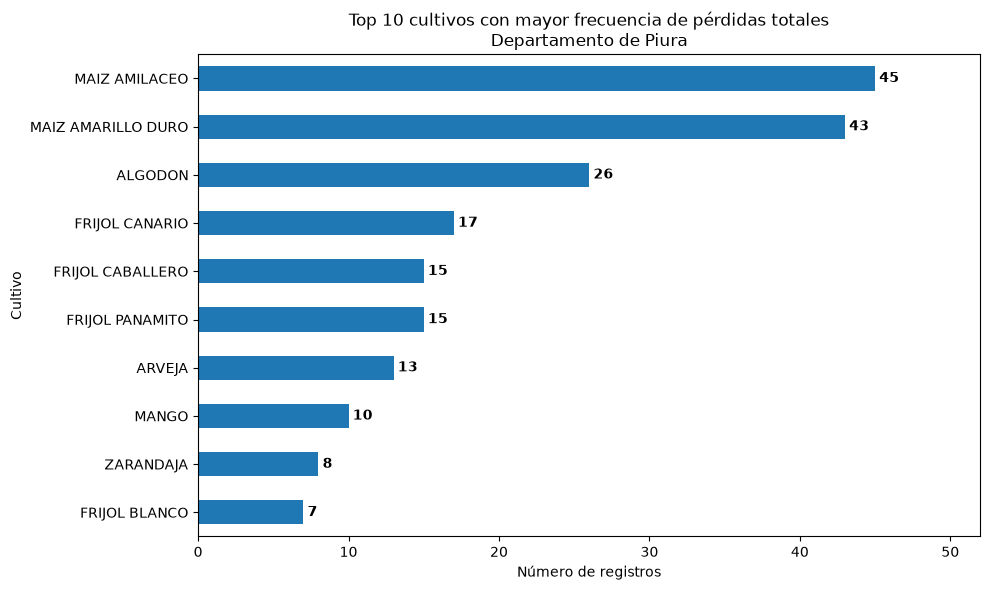

In [29]:
ax = ranking_cultivos_piura.plot(
    kind="barh",
    x="cultivo",
    y="frecuencia",
    figsize=(10, 6),
    legend=False
)

ax.set_title(
    "Top 10 cultivos con mayor frecuencia de pérdidas totales\nDepartamento de Piura"
)
ax.set_xlabel("Número de registros")
ax.set_ylabel("Cultivo")
ax.invert_yaxis()

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",          
        padding=3,        
        fontsize=10, 
        fontweight="bold" 
    )

ax.set_xlim(right=ax.get_xlim()[1] * 1.1) 
plt.tight_layout() 
plt.show()